<a href="https://colab.research.google.com/github/alexbedoni95-cpu/Analisi-Climatica-UE-e-Modellazione-Predittiva-2035-Progetto-Finale-EEA-/blob/main/Progetto_finale_aulab_richiesta_5_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Carica il file CSV nel DataFrame
df = pd.read_csv('/content/Renewable_Electricity_Production_Dataset.csv')

# Visualizza le prime 5 righe del DataFrame
display(df.head())

,Country and area,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,67.73,67.98,67.99,68.35,68.70,69.04,70.37,72.39,74.44,...,85.32,86.07,86.15,84.70,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,87.61,95.07,95.89,95.12,96.62,95.24,96.63,96.99,97.10,...,100.00,100.00,100.00,100.78,100.0,99.74,99.71,100.00,99.79,100.00
2,Algeria,0.84,1.69,1.09,1.82,0.83,0.98,0.63,0.35,0.42,...,0.40,0.32,0.25,0.84,NaN,NaN,NaN,NaN,NaN,NaN
3,Andorra,100.0,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,88.98,86.87,84.85,83.82,84.5,83.92,83.95,83.74,83.35,83.34
4,Angola,86.21,82.66,88.70,93.68,93.72,93.75,89.98,76.35,80.42,...,53.18,53.18,56.12,71.40,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
eu_countries = [
    'Austria',
    'Belgium',
    'Bulgaria',
    'Croatia',
    'Cyprus',
    'Czechia',
    'Denmark',
    'Estonia',
    'Finland',
    'France',
    'Germany',
    'Greece',
    'Hungary',
    'Ireland',
    'Italy',
    'Latvia',
    'Lithuania',
    'Luxembourg',
    'Malta',
    'Netherlands',
    'Poland',
    'Portugal',
    'Romania',
    'Slovakia',
    'Slovenia',
    'Spain',
    'Sweden'
]

# Melt the DataFrame to long format for easier plotting of time series
df_melted = df.melt(id_vars=['Country and area'], var_name='Year', value_name='Renewable Electricity Production')

# Convert 'Year' column to numeric, coercing errors will turn non-numeric values into NaN
df_melted['Year'] = pd.to_numeric(df_melted['Year'], errors='coerce')

# Drop rows where 'Year' is NaN (i.e., non-numeric column names that were not 'Country and area')
df_melted = df_melted.dropna(subset=['Year'])

# Filter for EU countries
df_eu = df_melted[df_melted['Country and area'].isin(eu_countries)]

# Filter for years between 2005 and 2023
df_eu_filtered = df_eu[(df_eu['Year'] >= 2005) & (df_eu['Year'] <= 2023)]

display(df_eu_filtered.head())

,Country and area,Year,Renewable Electricity Production
3371,Austria,2005,61.04
3378,Belgium,2005,2.41
3389,Bulgaria,2005,10.67
3408,Croatia,2005,54.33
3411,Cyprus,2005,0.02


Ora che abbiamo filtrato i dati per i paesi dell'UE e per l'intervallo di anni specificato, possiamo visualizzare i trend di produzione di elettricità da fonti rinnovabili per ciascun paese.

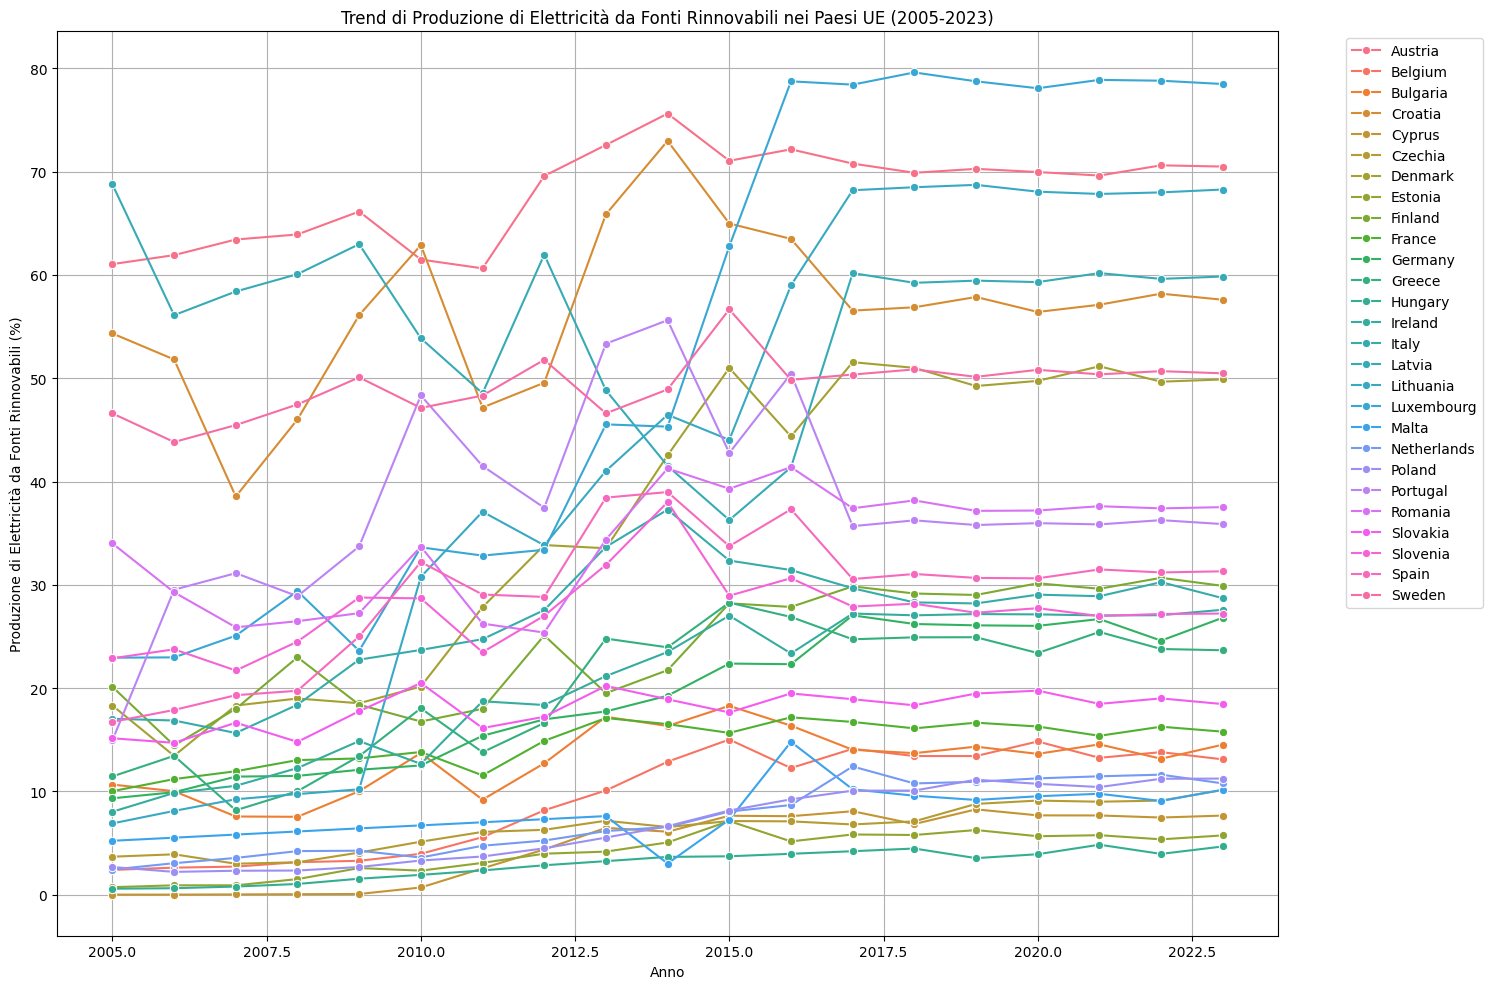

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the trends
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_eu_filtered, x='Year', y='Renewable Electricity Production', hue='Country and area', marker='o')

plt.title('Trend di Produzione di Elettricità da Fonti Rinnovabili nei Paesi UE (2005-2023)')
plt.xlabel('Anno')
plt.ylabel('Produzione di Elettricità da Fonti Rinnovabili (%)')
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()